## Exploratory Data Analysis

### Import Dependencies

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

NAMA_KELAS = {0: "NGR", 1: "Prediabetes", 2: "DM"}
WARNA = ["#2a78d6", "#eb6834", "#1baf7a"]

### Load Data

sel berisi spasi diubah dulu jadi nan, lalu diubah jadi angka, kecuali 3 kolom teks: data (tgl), EscDrinkD (penyakit yang bikin orang berhenti minum alkohol), dan EyeDia (ringkasan diagnosis mata).

In [27]:
KOLOM_TEKS = ["Data", "EscDrinkD", "EyeDia"]

df = pd.read_csv("data/Dataset for diabetes research.csv", encoding="gbk", dtype=str)
df = df.replace(r"^\s*$", np.nan, regex=True)

kolom_angka = df.columns.drop(KOLOM_TEKS)
df[kolom_angka] = df[kolom_angka].apply(pd.to_numeric, errors="coerce")

print("jumlah baris (orang):", df.shape[0])
print("jumlah kolom        :", df.shape[1])
df.head()

jumlah baris (orang): 5922
jumlah kolom        : 190


,Data,NO,VAR00001,Gender,Age,Age3Group,AgeGroup,Height,Weight,BMI,BMI4Class,overweight,obesity,WGOCobBMI,BMI25,waist1,WC9085,WC8580,WC9080,Waist2,hip,WHR,leg,HR,Bpsys,...,Compl,Check,GlucoseLev,DF,MADPN,TFDPN,DR,EyeDia,GAnum,filter,GAstudy,A1cover6575,DMhighrisk,FPGover7,P2PGover11,DRyd,cataract,GFR,GFR5lev,GFR6levG5,EUGFRabACR012,EUGFR90UACR01,EUGFR60abACR012,UACRGFR,DN
0,2/14/2012,733,1,1,31,1,2,168.0,65.5,23.207200,0.0,0.0,0.0,0.0,0.0,78.0,0.0,0.0,0.0,88.0,96.0,0.812500,NaN,78.0,110.0,...,9,9,9,1.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,1.0,1.0,0,0.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
1,2/11/2012,70,1,1,43,2,3,156.0,45.4,18.655490,0.0,0.0,0.0,0.0,0.0,74.0,0.0,0.0,0.0,84.0,88.0,0.840909,NaN,72.0,110.0,...,9,9,9,1.0,0.0,0.0,0.0,0,NaN,NaN,NaN,1.0,NaN,0,0.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
2,2/11/2012,98,1,1,57,2,4,163.0,69.1,26.007753,1.0,1.0,0.0,1.0,1.0,89.0,0.0,1.0,0.0,92.0,104.0,0.855769,NaN,72.0,110.0,...,1,2,2,1.0,0.0,0.0,0.0,0,NaN,NaN,NaN,1.0,1.0,0,0.0,0,0,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN
3,2/11/2012,127,1,1,69,3,5,163.0,57.7,21.717039,0.0,0.0,0.0,0.0,0.0,86.0,0.0,1.0,0.0,86.0,93.0,0.924731,NaN,72.0,120.0,...,2,2,2,1.0,0.0,0.0,0.0,左眼人工晶体,1.0,NaN,1.0,1.0,1.0,0,0.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
4,2/11/2012,129,1,1,46,2,3,170.0,60.0,20.761246,0.0,0.0,0.0,0.0,0.0,76.0,0.0,0.0,0.0,86.0,96.0,0.791667,NaN,76.0,120.0,...,2,1,9,1.0,0.0,0.0,0.0,0,1.0,NaN,1.0,1.0,1.0,0,0.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN


In [28]:
tanggal = pd.to_datetime(df["Data"], format="%m/%d/%Y")
print("survei dilakukan:", tanggal.min().date(), "s/d", tanggal.max().date())
print("id duplikasi    :", df["NO"].duplicated().sum())
print("id terbesar     :", df["NO"].max())
print("jumlah data     :", len(df), "orang")

survei dilakukan: 2012-02-10 s/d 2012-04-07
id duplikasi    : 0
id terbesar     : 6571
jumlah data     : 5922 orang


di kamus data (docx), gender 0 = perempuan, 1 = laki-laki. tapi di data isinya 1 dan 2.

In [29]:
df.groupby("Gender")[["Height", "HGB", "Fat"]].median()

,Height,HGB,Fat
Gender,,,
1,161.0,155.0,18.6
2,152.0,135.0,28.7


kode 1 = laki-laki karena lebih tinggi, bb lebih tinggi, lemak tubuh lebih rendah, dan 2 = perempuan.

- id sampe 6.571 padahal datanya 5.922 orang. ada 649 orang yg tidak ada di data.

### Missing Value

kolom tanpa data kosong   : 23
kolom kosong lebih dari 50%: 21


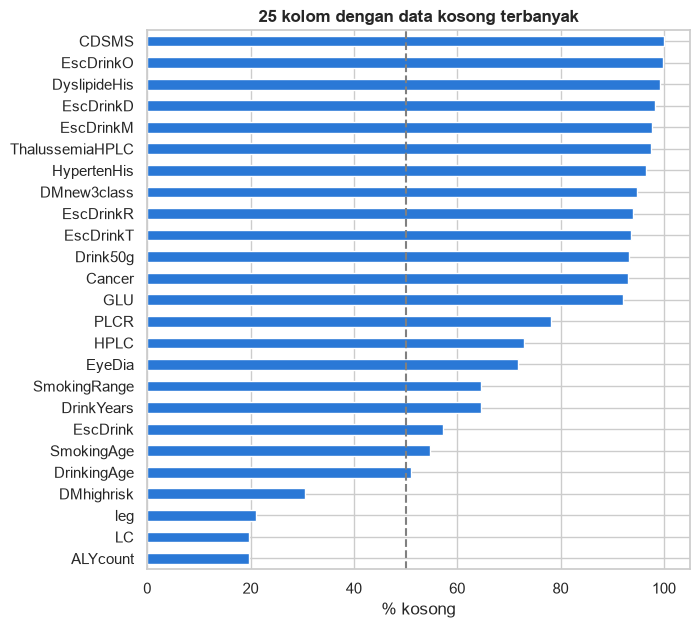

In [30]:
persen_kosong = df.isna().mean().mul(100).sort_values(ascending=False)

print("kolom tanpa data kosong   :", (persen_kosong == 0).sum())
print("kolom kosong lebih dari 50%:", (persen_kosong > 50).sum())

persen_kosong.head(25).plot.barh(figsize=(7, 7), color=WARNA[0])
plt.gca().invert_yaxis()
plt.axvline(50, color="gray", ls="--")
plt.title("25 kolom dengan data kosong terbanyak")
plt.xlabel("% kosong")
plt.show()

tidak semua kosong artinya data hilang:
1. kosong karena tidak ditanya, misal "umur mulai merokok" cuma ditanyakan ke perokok.
2. kosong artinya tidak. beberapa kolom cuma diisi angka 1 kalau jawabannya ya. contoh: hypertenhis (riwayat hipertensi),yang kosongnya diisi 0.

In [31]:
for kolom in ["HypertenHis", "DyslipideHis", "DMhighrisk"]:
    print(kolom, "sebelum:", df[kolom].value_counts(dropna=False).to_dict())

df[["HypertenHis", "DyslipideHis", "DMhighrisk"]] = df[["HypertenHis", "DyslipideHis", "DMhighrisk"]].fillna(0)

HypertenHis sebelum: {nan: 5722, 1.0: 200}
DyslipideHis sebelum: {nan: 5880, 1.0: 42}
DMhighrisk sebelum: {1.0: 4115, nan: 1807}


### Distribusi Target

label yg dipakai: PGclass3 (0 = NGR, 1 = Prediabetes, 2 = DM)
tujuan: mencari orang yg belum tahu dirinya diabetes/prediabetes. 

jadi orang yg sudah pernah didiagnosis DM (DMhis = 1) dikeluarkan.

data awal : 5922 orang
df_scr    : 5873 orang ( 49 orang yg sudah tahu DM dikeluarkan)


,jumlah,persen
PGclass3,,
NGR,4444,75.7
Prediabetes,1121,19.1
DM,308,5.2


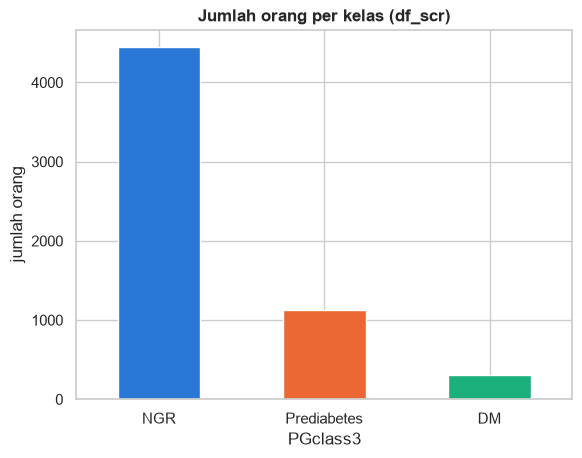

In [32]:
df_scr = df[df["DMhis"] == 0].copy()
print("data awal :", len(df), "orang")
print("df_scr    :", len(df_scr), "orang (", len(df) - len(df_scr), "orang yg sudah tahu DM dikeluarkan)")

jumlah = df_scr["PGclass3"].map(NAMA_KELAS).value_counts()
persen = (jumlah / jumlah.sum() * 100).round(1)
display(pd.DataFrame({"jumlah": jumlah, "persen": persen}))

jumlah.plot.bar(color=WARNA, rot=0)
plt.title("Jumlah orang per kelas (df_scr)")
plt.ylabel("jumlah orang")
plt.show()

orang sehat (NGR) jauh lebih banyak, 14 kali jumlah DM.

### Leak Feature

#### Gula Darah

label dibuat pakai aturan WHO 1999:
1. DM kalau FPG ≥ 7,0 atau PG2h ≥ 11,1 (atau sudah punya riwayat DM)
2. Prediabetes kalau FPG ≥ 6,1 atau PG2h ≥ 7,8
3. sisanya NGR

In [33]:
kondisi_dm = (df["FPG"] >= 7.0) | (df["PG2h"] >= 11.1) | (df["DMhis"] == 1)
kondisi_pre = (df["FPG"] >= 6.1) | (df["PG2h"] >= 7.8)
label_tebakan = np.select([kondisi_dm, kondisi_pre], [2, 1], default=0)

cocok = (label_tebakan == df["PGclass3"]).sum()
print(f"label hasil aturan WHO sama dengan label asli: {cocok} dari {len(df)} orang")

label hasil aturan WHO sama dengan label asli: 5922 dari 5922 orang


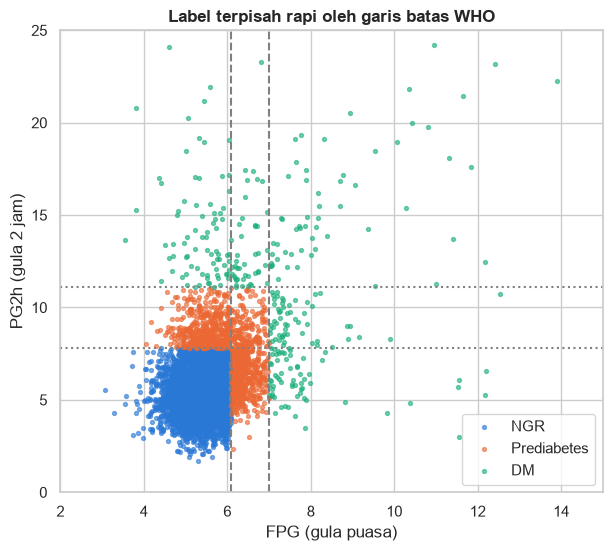

In [34]:
plt.figure(figsize=(7, 6))
for kelas, nama in NAMA_KELAS.items():
    d = df[df["PGclass3"] == kelas]
    plt.scatter(d["FPG"], d["PG2h"], s=8, alpha=0.6, color=WARNA[kelas], label=nama)
plt.axvline(6.1, color="gray", ls="--"); plt.axvline(7.0, color="gray", ls="--")
plt.axhline(7.8, color="gray", ls=":"); plt.axhline(11.1, color="gray", ls=":")
plt.xlim(2, 15); plt.ylim(0, 25)
plt.xlabel("FPG (gula puasa)"); plt.ylabel("PG2h (gula 2 jam)")
plt.title("Label terpisah rapi oleh garis batas WHO")
plt.legend()
plt.show()

leak feature karena label 100 bisa dihitung ulang dari FPG dan PG2h. 

#### VAR00001

isinya cuma 1 atau 9

In [35]:
pd.crosstab(df["VAR00001"], df["PGclass3"].map(NAMA_KELAS))[["NGR", "Prediabetes", "DM"]]

PGclass3,NGR,Prediabetes,DM
VAR00001,,,
1,4444,637,246
9,0,484,111


nilai 9 tidak pernah muncul di orang sehat (NGR), hanya di prediabetes dan DM. 

#### ThalussemiaAND

thalassemia: kelainan darah

In [36]:
pd.crosstab(df["ThalussemiaAND"], df["PGclass3"].map(NAMA_KELAS))[["NGR", "Prediabetes", "DM"]]

PGclass3,NGR,Prediabetes,DM
ThalussemiaAND,,,
0.0,4442,822,260
1.0,2,290,81


nilai 1 cuma ada 2 orang di NGR, tapi ratusan di prediabetes & DM. kolom ini cuma diisi untuk orang yg gula darahnya tidak normal.

#### Conclusion

In [37]:
BOCOR = [
    "FPG", "PG2h", "GLU", "DMhis",                       # gula darah & riwayat DM 
    "HomaIR", "Homaβ", "ISIGutt", "INS2h", "CP2h",      # dihitung dari gula darah / butuh tes OGTT
    "FPGover7", "P2PGover11",                            # penanda FPG / PG2h tinggi
    "DM", "DMnew3class", "PGclass6", "PGclass3",         # label itu sendiri
    "VAR00001", "ThalussemiaAND",                        
]
TIDAK_DIPAKAI = [
    "HbA1c", "HPLC", "GA", "A1cover6575",                # tes gula darah lain
    "filter", "GAstudy", "GAnum",                        # penanda subjek studi
    "Known", "OPD", "ToChilren", "DietExcise", "Compl", "Check", "GlucoseLev",  # kuesioner, mayoritas "tidak tahu"
    "DF", "MADPN", "TFDPN", "DR", "DRyd",                # komplikasi diabetes
    "CDSMS",                                             # 100% kosong
]
print("kolom bocor        :", len(BOCOR))
print("kolom tidak dipakai:", len(TIDAK_DIPAKAI))

kolom bocor        : 17
kolom tidak dipakai: 20


### Used Features

kolom yang dibuang:
- kolom teks dan id
- kolom yg kosong lebih dari 50%
- kolom yg isinya cuma 1 nilai atau tidak ada variasi
- ALT.1 (isinya cuma akar dari ALT, jadi double)

In [38]:
buang = set(BOCOR + TIDAK_DIPAKAI + KOLOM_TEKS + ["NO", "ALT.1"])
kosong_banyak = df.columns[df.isna().mean() > 0.5]
cuma_satu_nilai = df_scr.columns[df_scr.nunique() <= 1]

fitur = [c for c in df.columns if c not in buang and c not in kosong_banyak and c not in cuma_satu_nilai]
print("jumlah fitur yg tersisa:", len(fitur))

jumlah fitur yg tersisa: 135


### Feature Distribution

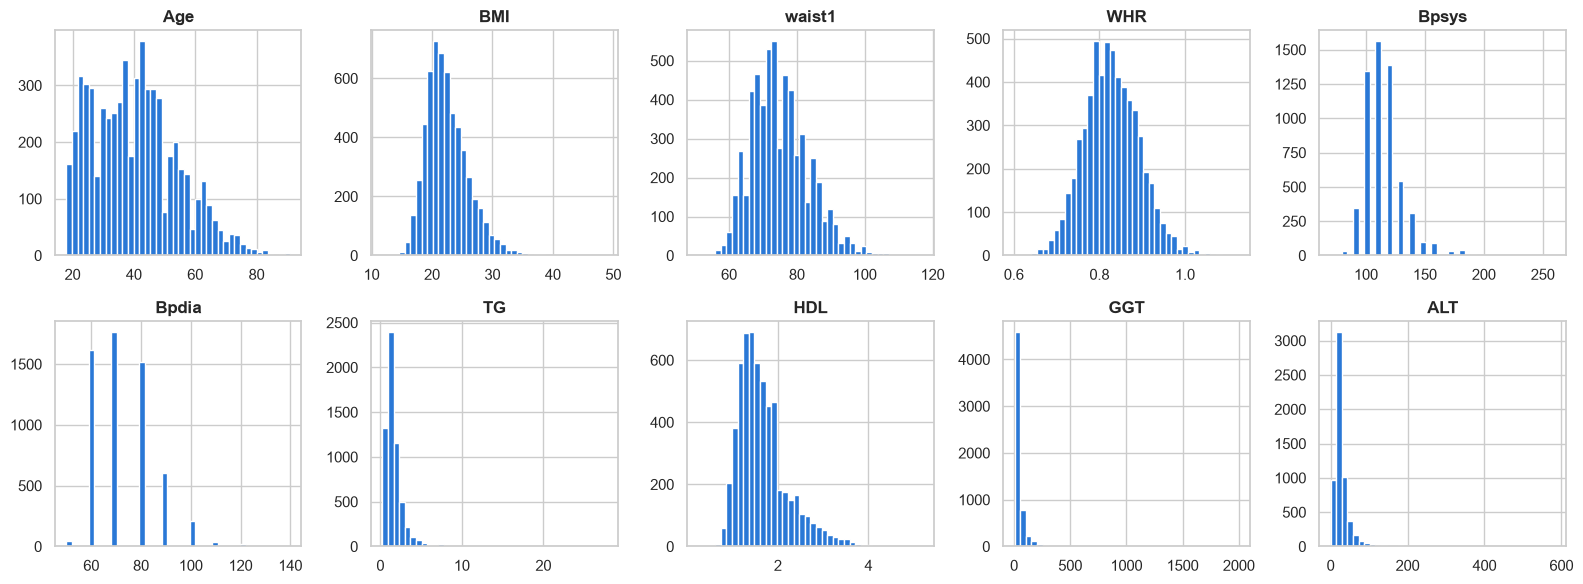

In [39]:
FITUR_UTAMA = ["Age", "BMI", "waist1", "WHR", "Bpsys", "Bpdia", "TG", "HDL", "GGT", "ALT"]

fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, kolom in zip(axes.flat, FITUR_UTAMA):
    ax.hist(df[kolom].dropna(), bins=40, color=WARNA[0])
    ax.set_title(kolom)
plt.tight_layout()
plt.show()

- Age = umur
- BMI = indeks massa tubuh
- waist1 = lingkar pinggang
- WHR = rasio pinggang-pinggul
- Bpsys/Bpdia = tensi atas/bawah
- TG = trigliserida
- HDL = kolesterol baik
- GGT dan ALT = enzim hati

 beberapa hasil lab (TG, GGT, ALT) miring ke kanan: kebanyakan orang nilainya kecil, sedikit orang nilainya sangat besar

### Feature Comparison

fitur apa yg beda antara orang sehat, prediabetes, dan DM, tanpa tes gula darah?

#### Fitur Angka

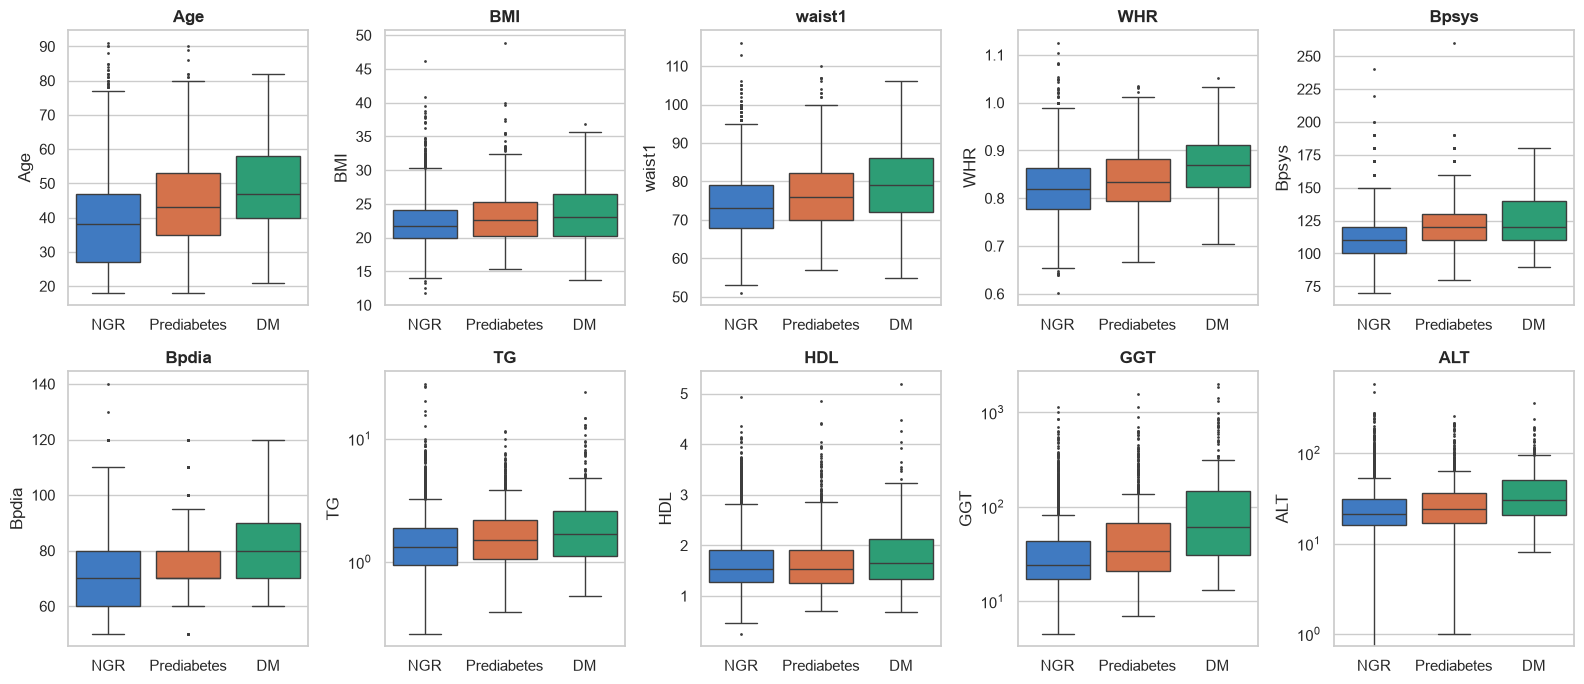

In [40]:
df_scr["kelas"] = df_scr["PGclass3"].map(NAMA_KELAS)
urutan = ["NGR", "Prediabetes", "DM"]

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, kolom in zip(axes.flat, FITUR_UTAMA):
    sns.boxplot(data=df_scr, x="kelas", y=kolom, order=urutan, hue="kelas", hue_order=urutan,
                palette=WARNA, ax=ax, fliersize=1, legend=False)
    ax.set_title(kolom); ax.set_xlabel("")
    if kolom in ["TG", "GGT", "ALT"]:
        ax.set_yscale("log")   
plt.tight_layout()
plt.show()

In [41]:
df_scr.groupby("kelas")[FITUR_UTAMA].median().loc[urutan].T.round(2)

kelas,NGR,Prediabetes,DM
Age,38.00,43.00,47.00
BMI,21.70,22.61,23.08
waist1,73.00,76.00,79.00
WHR,0.82,0.83,0.87
Bpsys,110.00,120.00,120.00
Bpdia,70.00,70.00,80.00
TG,1.32,1.50,1.69
HDL,1.54,1.54,1.65
GGT,24.00,34.00,61.00
ALT,21.00,24.00,30.00


#### Categorical

In [42]:
kategori = pd.DataFrame({
    "laki-laki (%)": df_scr["Gender"] == 1,
    "tensi tinggi, BP13085 (%)": df_scr["BP13085"] == 1,
    "obesitas perut, WC9085 (%)": df_scr["WC9085"] == 1,
    "kelompok risiko tinggi, DMhighrisk (%)": df_scr["DMhighrisk"] == 1,
    "riwayat DM keluarga (%)": df_scr["DMfamilyHistory"] == 1,
})
(kategori.groupby(df_scr["kelas"]).mean() * 100).loc[urutan].T.round(1)

kelas,NGR,Prediabetes,DM
laki-laki (%),43.6,52.5,69.5
"tensi tinggi, BP13085 (%)",18.8,30.2,51.9
"obesitas perut, WC9085 (%)",6.4,12.0,24.4
"kelompok risiko tinggi, DMhighrisk (%)",65.1,80.2,89.6
riwayat DM keluarga (%),1.6,1.9,2.3


- DM vs NGR bedanya cukup jelas: orang DM lebih tua, tensinya lebih tinggi, pinggangnya lebih besar, dan enzim hati GGT-nya jauh lebih tinggi. proporsi laki-laki juga lebih banyak di DM.
- Prediabetes vs NGR bedanya tipis: polanya sama tapi selisihnya kecil. jadi, prediabetes kemungkinan paling susah dideteksi tanpa tes gula darah.

### Outlier

cek nilai yg tidak masuk akal secara medis

In [43]:
print("tinggi < 120 cm                 :", (df["Height"] < 120).sum())
print("tensi atas <= tensi bawah       :", (df["Bpsys"] <= df["Bpdia"]).sum())
print("LDL > kolesterol total          :", (df["LDL"] > df["CHOL"]).sum())
print("kreatinin < 35 (terlalu rendah) :", (df["SCRE"] < 35).sum())
print("eGFR > 200 (terlalu tinggi)     :", (df["GFR"] > 200).sum())

tinggi < 120 cm                 : 2
tensi atas <= tensi bawah       : 2
LDL > kolesterol total          : 3
kreatinin < 35 (terlalu rendah) : 330
eGFR > 200 (terlalu tinggi)     : 376


kreatinin (SCRE): terlalu banyak yang nilainya terlalu rendah untuk orang dewasa. karena eGFR (GFR) dihitung dari kreatinin, eGFR mereka jadi terlalu tinggi. 

1. data: 5.922 orang × 190 kolom, survei Feb–Apr 2012. Gender: 1 = laki-laki, 2 = perempuan.
2. missing value: banyak kolom kosong, tapi sebagian kosongnya wajar atau artinya "tidak" (sudah diisi 0).
3. imbalanced class.
4. leakage: kolom FPG dan PG2h. semua kolom gula darah, turunannya, VAR00001, dan ThalussemiaAND.
5. DM bisa dibedakan lewat umur, tensi, lingkar pinggang, dan GGT. prediabetes jauh lebih sulit dibedakan dari orang sehat.
7. outlier: kreatinin dan eGFR banyak yg tidak masuk akal.

belum cek redundansi fitur, bmi punya 5 versi kategori

### Feature Redundancy

#### BMI

selain kolom BMI (angka), ada 5 kolom lain yg isinya cuma potongan dari BMI.

In [44]:
versi_bmi = ["BMI", "BMI4Class", "overweight", "obesity", "BMI25", "WGOCobBMI"]
print("yg masih ada di fitur:", [c for c in versi_bmi if c in fitur])

df_scr.groupby("BMI4Class")["BMI"].agg(["min", "max", "count"])

yg masih ada di fitur: ['BMI', 'BMI4Class', 'overweight', 'obesity', 'BMI25', 'WGOCobBMI']


,min,max,count
BMI4Class,,,
-1.0,11.800639,18.497159,544
0.0,18.501784,24.999036,4014
1.0,25.015609,29.982423,1018
2.0,30.000000,48.846881,186


tiap kelas BMI4Class cuma rentang angka BMI. kalau BMI (angka) sudah dipakai, BMI4Class tidak menambah info baru. hal yg sama berlaku untuk overweight, obesity, BMI25, WGOCobBMI.

#### Feature Correlation

korelasi spearman:
- mendekati 1: kalau satu naik, yg lain ikut naik
- mendekati -1: kalau satu naik, yg lain turun
- mendekati 0: tidak ada hubungan

pakai spearman karena banyak fitur miring ke kanan dan banyak fitur kategori.

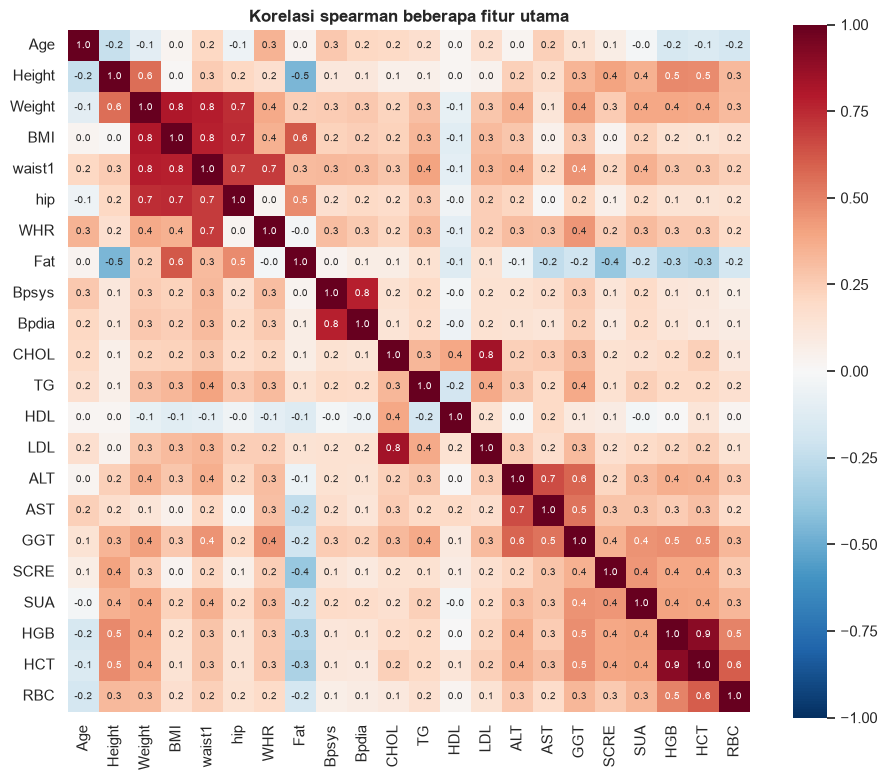

In [45]:
FITUR_KORELASI = ["Age", "Height", "Weight", "BMI", "waist1", "hip", "WHR", "Fat",
                  "Bpsys", "Bpdia", "CHOL", "TG", "HDL", "LDL", "ALT", "AST", "GGT",
                  "SCRE", "SUA", "HGB", "HCT", "RBC"]
korelasi = df_scr[FITUR_KORELASI].corr(method="spearman")

plt.figure(figsize=(11, 9))
sns.heatmap(korelasi, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".1f",
            annot_kws={"fontsize": 7}, square=True)
plt.title("Korelasi spearman beberapa fitur utama")
plt.show()

cek semua fitur, cari pasangan dengan korelasi |r| ≥ 0,9 (hampir sama isinya).

In [46]:
korelasi_semua = df_scr[fitur].corr(method="spearman")

pasangan = korelasi_semua.where(np.triu(np.ones(korelasi_semua.shape, dtype=bool), k=1)).stack().reset_index()
pasangan.columns = ["fitur_1", "fitur_2", "r"]
pasangan_tinggi = pasangan[pasangan["r"].abs() >= 0.9].sort_values("r", ascending=False).reset_index(drop=True)

print("jumlah pasangan |r| >= 0.9:", len(pasangan_tinggi))
pasangan_tinggi.round(3)

jumlah pasangan |r| >= 0.9: 56


,fitur_1,fitur_2,r
0,GFR5lev,GFR6levG5,1.000
1,ACR3degree,HighACR,1.000
2,EUGFR90UACR01,EUGFR60abACR012,0.999
3,HighUmALB,DN,0.997
4,CerebralHe,CerebralIn,0.986
5,CAP,Hypo14,0.983
6,LC,LCcount,0.981
7,PAD,Hyper16,0.978
8,CerebralHe,MI,0.978
9,MI,HF,0.978


banyak pasangan dari kolom riwayat penyakit (Angina, PAD, MI, HF, dll). kenapa?

In [47]:
RIWAYAT = ["Angina", "Arrhythmia", "PAD", "Hyper16", "Hyper13", "Blind", "CerebralHe", "CerebralIn",
           "TIA", "MI", "HF", "CAP", "Hypo14", "RF", "Amputation"]

semua_9 = (df_scr[RIWAYAT] == 9).all(axis=1).sum()
print(f"total pertanyaan riwayat penyakit: {len(RIWAYAT)}")
print(f"orang yg jawab \"9\" (tidak tahu): {semua_9}")

dua_duanya_riwayat = pasangan_tinggi["fitur_1"].isin(RIWAYAT) & pasangan_tinggi["fitur_2"].isin(RIWAYAT)
print("pasangan yg dua-duanya kolom riwayat penyakit:", dua_duanya_riwayat.sum())
print("pasangan sisanya:", (~dua_duanya_riwayat).sum())

total pertanyaan riwayat penyakit: 15
orang yg jawab "9" (tidak tahu): 689
pasangan yg dua-duanya kolom riwayat penyakit: 37
pasangan sisanya: 19


- 689 orang jawab "tidak tahu" (9) di semua pertanyaan riwayat penyakit. kolom-kolom tersebut berkorelasi bukan karena penyakitnya berhubungan, tapi karena kode 9.
- sisanya redundansi:
  - GFR5lev dan GFR6levG5: kategori GFR dengan pembagian beda
  - ACR3degree dan HighACR: kategori albumin urin
  - Age dan AgeGroup, Age3Group: umur dan kelompok umur
  - Smoking dan Smoking2: status merokok
  - LC dan LCcount, EO dan EOcount, ALY dan ALYcount: persen dan jumlah sel darah
  - TBIL dan IDBIL: bilirubin total dan bilirubin indirek
  - HGB dan HCT: hemoglobin dan hematokrit